# Image Representation with Neural Fields

Train neural field models to represent a single image as a continuous function
mapping `(x, y)` coordinates to RGB values.

## Setup

In [1]:
import math

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch

import neurofield as nf

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


## Load Image

Image size: 768 x 512


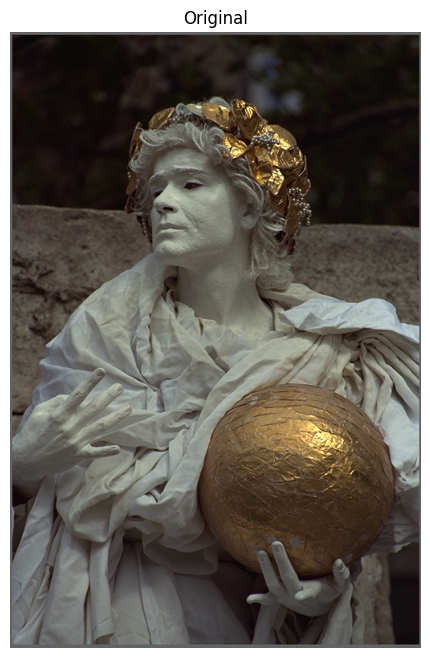

In [2]:
IMAGE_PATH = "../data/Kodak/kodim17.png"


img = Image.open(IMAGE_PATH)
W, H = img.size
print(f"Image size: {H} x {W}")
plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.title("Original")
plt.show()

## Model Configurations

Every neural field has about 200k parameters, so results compare architectures
at equal capacity. Hyperparameters follow each method's official code;
`# deviation` comments mark the few changes needed under this protocol.

In [3]:
CONFIGS = [
    {
        "name": "RFF",  # Tancik et al. (NeurIPS 2020), 2D image regression
        "class": nf.RFF,
        "kwargs": {
            "hidden_features": 212,
            "hidden_layers": 3,
            "num_frequencies": 256,
            "sigma": 5.0,  # sigma 10 on [0, 1] coordinates equals 5 on [-1, 1]
            "output_activation": torch.tanh,
        },
        "lr": 1e-3,
    },
    {
        "name": "PE-MLP",  # FINER image benchmark
        "class": nf.PEMLP,
        "kwargs": {
            "hidden_features": 248,
            "hidden_layers": 4,
            "num_frequencies": 10,
            "output_activation": torch.tanh,
        },
        "lr": 1e-3,
    },
    {
        "name": "MFN",  # GaborNet (Fathony et al., ICLR 2021)
        "class": nf.MFN,
        "kwargs": {
            "hidden_features": 252,
            "hidden_layers": 4,
            # deviation: the official input_scale 256 and alpha 6 (tuned for
            # 256 x 256 images) are 6 dB worse here.
            "input_scale": 1024.0,
            "alpha": 1.25,
            "beta": 0.125,
            "weight_scale": 1.0,
            "output_activation": torch.tanh,
        },
        "lr": 1e-2,
    },
    {
        "name": "SIREN",  # FINER image benchmark
        "class": nf.SIREN,
        "kwargs": {
            "hidden_features": 256,
            "hidden_layers": 4,
            "omega": 30.0,
            "output_activation": torch.tanh,
        },
        "lr": 1e-3,
    },
    {
        "name": "Gauss",  # FINER image benchmark
        "class": nf.Gauss,
        "kwargs": {
            "hidden_features": 256,
            "hidden_layers": 4,
            "scale": 30.0,
            "output_activation": torch.tanh,
        },
        "lr": 1e-3,  # deviation: the published 5e-3 is unstable on some images
    },
    {
        "name": "WIRE",  # FINER image benchmark, real Gabor layer
        "class": nf.RealWIRE,
        "kwargs": {
            "hidden_features": 256,
            "hidden_layers": 4,
            "omega": 20.0,
            "scale": 10.0,
            "output_activation": torch.tanh,
        },
        "lr": 3e-3,  # deviation: the official 5e-3 diverges for the real Gabor layer
    },
    {
        "name": "FINER",  # FINER image benchmark
        "class": nf.FINER,
        "kwargs": {
            "hidden_features": 256,
            "hidden_layers": 4,
            "omega": 30.0,
            "output_activation": torch.tanh,
        },
        "lr": 1e-3,
    },
    {
        "name": "Instant-NGP",  # instant-ngp configs/image/base.json
        "class": nf.InstantNGP,
        "kwargs": {
            "num_levels": 19,  # deviation: 16 in the reference; 19 meets the budget
            "features_per_level": 2,
            "log2_hashmap_size": 13,
            "base_resolution": 16,
            "max_resolution": max(H, W) // 2,
            "hidden_features": 64,
            "hidden_layers": 2,
            "output_activation": torch.tanh,
        },
        "lr": 1e-2,
        "train_kwargs": {"adam_betas": (0.9, 0.99), "adam_eps": 1e-15},
    },
    {
        "name": "TensoRF",
        "class": nf.TensoRF,
        "kwargs": {
            "rank": 176,
            "resolution": 256,
            "mode": "cp",
            "hidden_features": 256,
            "hidden_layers": 2,
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,
    },
    {
        "name": "GA-Planes",
        "class": nf.GAPlanes,
        "kwargs": {
            "features": 25,
            "resolution": (256, 64),
            "hidden_features": 256,
            "hidden_layers": 2,
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,
    },
    {
        "name": "FUTON (sinc)",
        "class": nf.FUTON,
        "kwargs": {
            "basis": (
                "sinc",
                {"num_components": (H // 2, W // 2), "grid_size": (H, W)},
            ),
            "combiner": ("cp", {"rank": 224}),
            "decoder": ("mlp", {"hidden_layers": 1}),
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,
    },
    {
        "name": "FUTON (Lanczos)",
        "class": nf.FUTON,
        "kwargs": {
            "basis": ("lanczos", {"num_components": (H // 2, W // 2), "radius": 3}),
            "combiner": ("cp", {"rank": 224}),
            "decoder": ("mlp", {"hidden_layers": 1}),
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,
    },
]

## Train Models

In [4]:
results = []

for config in CONFIGS:
    torch.manual_seed(0)

    train_dataset = nf.ImageCoordinateDataset(IMAGE_PATH, subsample=0.1)
    eval_dataset = nf.ImageCoordinateDataset(IMAGE_PATH)

    model = config["class"](in_features=2, out_features=3, **config["kwargs"])
    num_params = nf.count_parameters(model, trainable_only=False)

    print(f"\n--- {config['name']} ({num_params:,} params) ---")
    res = nf.train(
        model=model,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        lr=config["lr"],
        num_epochs=2000,
        metrics={
            "psnr": nf.psnr,
            "ssim": nf.ssim,
            "ms_ssim": nf.ms_ssim,
            "lpips": nf.lpips,
        },
        log_interval=100,
        eval_interval=100,
        device=device,
        **config.get("train_kwargs", {}),
    )

    output = nf.chunked_inference(model, eval_dataset.input, device=device)
    recon = eval_dataset.postprocess(output.cpu())

    res["config"]["model"] = config["name"]
    res["reconstructed"] = recon
    results.append(res)

    del model, recon, res["model_dict"]
    torch.cuda.empty_cache()


--- RFF (199,707 params) ---

--- PE-MLP (196,667 params) ---

--- MFN (198,075 params) ---

--- SIREN (198,915 params) ---

--- Gauss (198,915 params) ---

--- WIRE (199,284 params) ---

--- FINER (198,915 params) ---

--- Instant-NGP (195,296 params) ---

--- TensoRF (201,987 params) ---

--- GA-Planes (194,819 params) ---

--- FUTON (sinc) (194,435 params) ---

--- FUTON (Lanczos) (194,435 params) ---


## Collect Results

In [5]:
records = []
for res in results:
    for entry in res["history"]:
        if "eval" not in entry:
            continue

        records.append(
            {
                "Model": res["config"]["model"],
                "# Params (k)": res["config"]["num_params"] / 1000,
                "Iteration": entry["epoch"],
                "Time (s)": entry["elapsed"],
                "Speed (img/s)": 1.0 / entry["eval"]["duration"],
                "PSNR (dB)": entry["eval"]["psnr"],
                "SSIM": entry["eval"]["ssim"],
                "LPIPS": entry["eval"]["lpips"],
            }
        )


records = pd.DataFrame(records)

## Convergence Performance

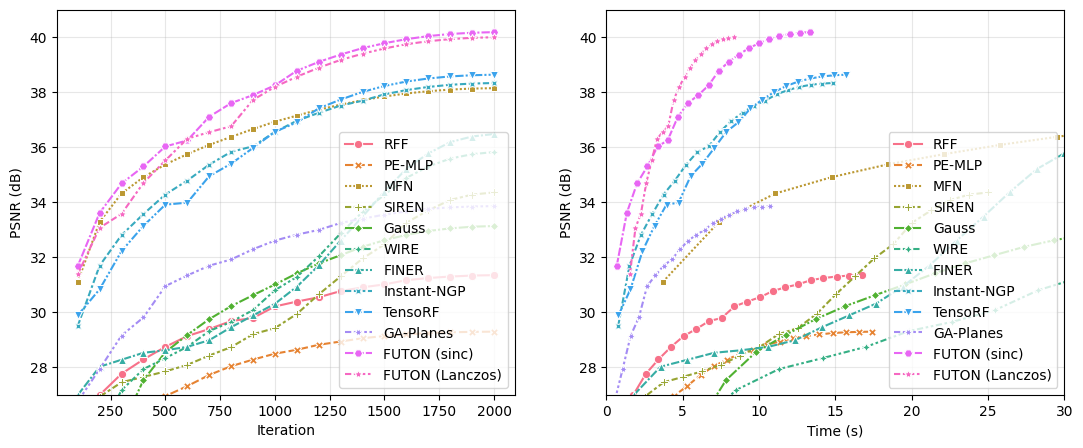

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.lineplot(
    data=records,
    x="Iteration",
    y="PSNR (dB)",
    hue="Model",
    style="Model",
    markers=True,
    ax=axes[0],
)
axes[0].set_ylim(27, 41)
axes[0].grid(alpha=0.3)
axes[0].legend(loc="lower right")

sns.lineplot(
    data=records,
    x="Time (s)",
    y="PSNR (dB)",
    hue="Model",
    style="Model",
    markers=True,
    ax=axes[1],
)
axes[1].set_xlim(0, 30)
axes[1].set_ylim(27, 41)
axes[1].grid(alpha=0.3)
axes[1].legend(loc="lower right")

plt.show()

## Results Summary

In [7]:
summary = (
    records.groupby("Model")
    .agg(
        {
            "# Params (k)": "first",
            "Iteration": "last",
            "Time (s)": "last",
            "Speed (img/s)": "mean",
            "PSNR (dB)": "last",
            "SSIM": "last",
            "LPIPS": "last",
        }
    )
    .sort_values("PSNR (dB)", ascending=False)
    .reset_index()
)
display(summary)

,Model,# Params (k),Iteration,Time (s),Speed (img/s),PSNR (dB),SSIM,LPIPS
0,FUTON (sinc),194.435,2000,13.331653,38.661266,40.185284,0.965744,0.089055
1,FUTON (Lanczos),194.435,2000,8.344274,93.709791,39.999416,0.964196,0.090552
2,TensoRF,201.987,2000,15.720232,48.045593,38.637951,0.952021,0.132417
3,Instant-NGP,195.296,2000,14.845252,26.875725,38.334995,0.952669,0.128409
4,MFN,198.075,2000,73.739403,7.447119,38.147987,0.946932,0.149081
5,FINER,198.915,2000,35.279927,11.618258,36.480553,0.945038,0.159598
6,WIRE,199.284,2000,56.791946,11.651984,35.824490,0.929369,0.191459
7,SIREN,198.915,2000,25.018674,24.096921,34.357227,0.925894,0.213699
8,GA-Planes,194.819,2000,10.713694,61.686165,33.859844,0.903021,0.238308
9,Gauss,198.915,2000,39.119335,14.904843,33.134541,0.882818,0.254744


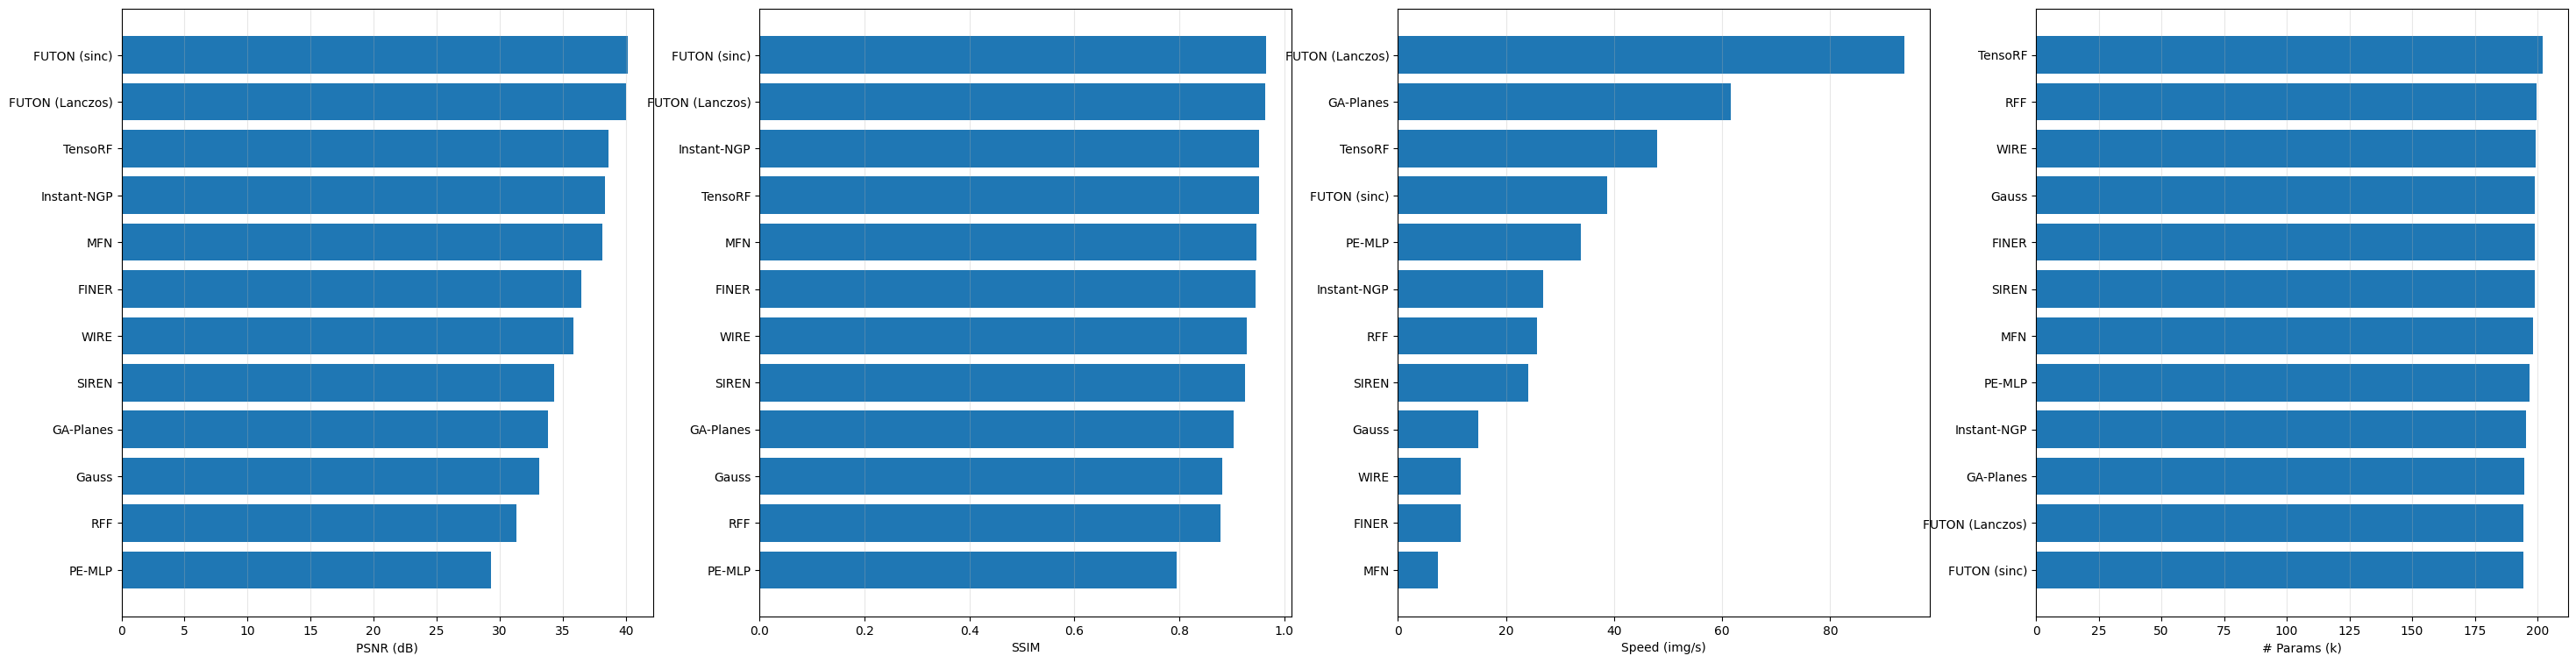

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(36, 9))

for ax, metric in zip(axes, ["PSNR (dB)", "SSIM", "Speed (img/s)", "# Params (k)"]):
    summary_sorted = summary.sort_values(metric, ascending=True)
    ax.barh(summary_sorted["Model"], summary_sorted[metric])
    ax.set_xlabel(metric)
    ax.grid(axis="x", alpha=0.3)

plt.show()

## Visual Comparison

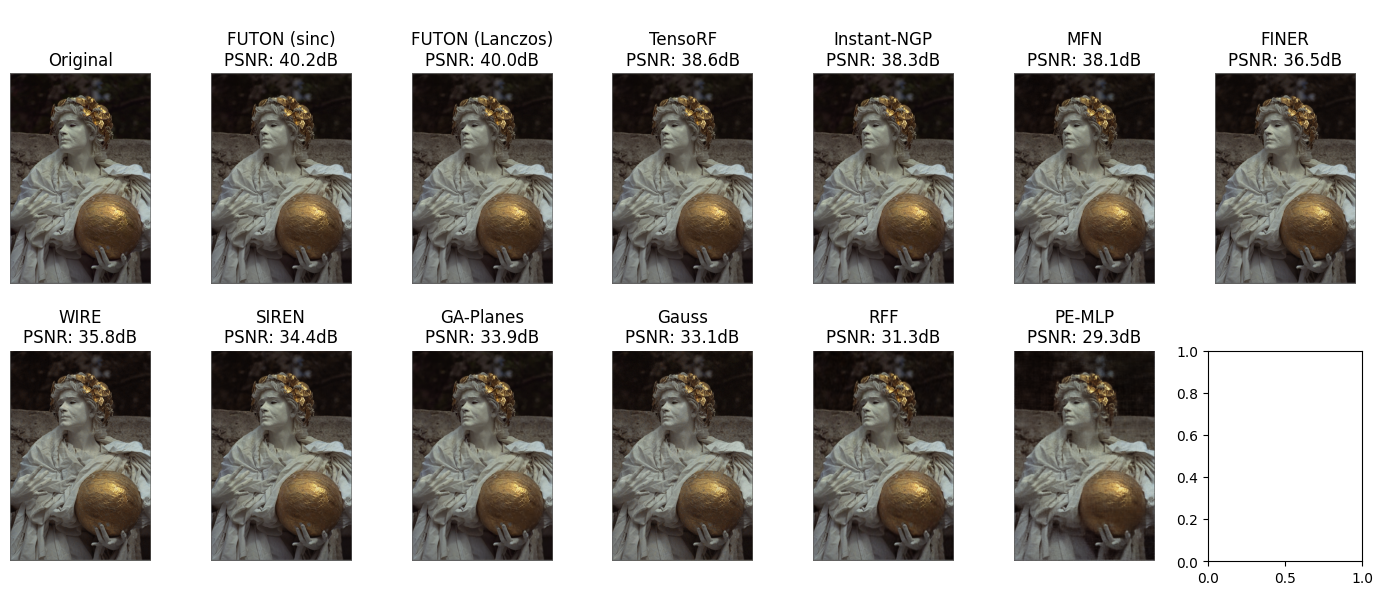

In [9]:
psnr_lookup = summary.set_index("Model")["PSNR (dB)"]
sorted_results = sorted(
    results, key=lambda r: psnr_lookup[r["config"]["model"]], reverse=True
)

items = [("Original", eval_dataset.original)] + [
    (res["config"]["model"], res["reconstructed"]) for res in sorted_results
]
num_cols = math.ceil(len(items) / 2)
fig, axes = plt.subplots(2, num_cols, figsize=(2 * num_cols, 6))

for idx, (name, img) in enumerate(items):
    ax = axes[idx // num_cols, idx % num_cols]
    ax.imshow(img.permute(1, 2, 0))
    title = name if name == "Original" else f"\n{name}\nPSNR: {psnr_lookup[name]:.1f}dB"
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()